### Feature Transformation Using PCA

In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
# Load the dataset

df = pd.read_csv('./datasets/assignment-01.csv')

df.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [3]:
# Dataset exploration

print("Dataset shape:", df.shape)
print("\n Column names")
print(df.columns)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDataset information:")
df.info()

Dataset shape: (178, 14)

 Column names
Index(['Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcanity', 'Magnesium',
       'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols',
       'Proanthocyanins', 'Color_Intensity', 'Hue', 'OD280', 'Proline',
       'Customer_Segment'],
      dtype='object')

Missing values:
Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
Customer_Segment        0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non

In [4]:
# Seperate the features and class labels

X = df.drop('Customer_Segment', axis=1)
y = df['Customer_Segment']

print("\nFeatures shape:", X.shape)
print("Class labels shape:", y.unique())


Features shape: (178, 13)
Class labels shape: [1 2 3]


In [5]:
# Standardize the features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("\nStandardized features shape:", X_scaled.shape)


Standardized features shape: (178, 13)


In [6]:
# Apply PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)
print("Original number of features:", X.shape[1])
print("Number of features after PCA:", X_pca.shape[1])

Original number of features: 13
Number of features after PCA: 13


In [7]:
# Display explained variance
variance = pca.explained_variance_ratio_
print("\nExplained variance ratio:", variance)
print("\nCumulative explained variance:", np.cumsum(variance))


Explained variance ratio: [0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]

Cumulative explained variance: [0.36198848 0.55406338 0.66529969 0.73598999 0.80162293 0.85098116
 0.89336795 0.92017544 0.94239698 0.96169717 0.97906553 0.99204785
 1.        ]


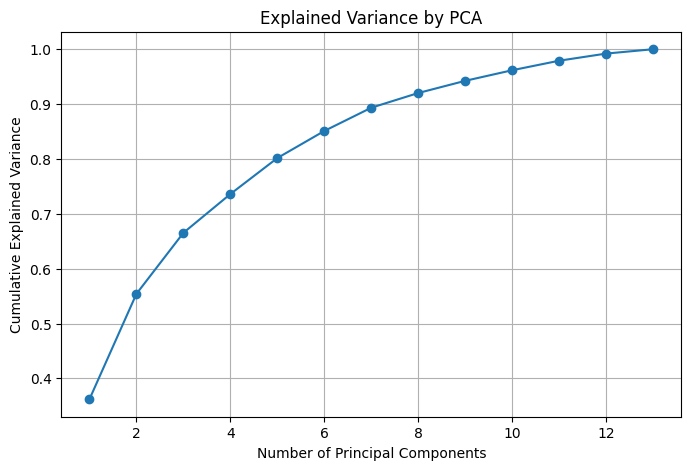

In [8]:
# Plot explained variance
plt.figure(figsize=(8, 5))

plt.plot(range(1,len(variance)+1),np.cumsum(variance),marker='o')

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title("Explained Variance by PCA")
plt.grid(True)

plt.show()

In [9]:
#Reduced the data to two principal components
reduced_data = pd.DataFrame(
    X_pca[:,:2],
    columns=['PC1','PC2']
)
reduced_data.head()

,PC1,PC2
0,3.316751,1.443463
1,2.209465,-0.333393
2,2.516740,1.031151
3,3.757066,2.756372
4,1.008908,0.869831


In [10]:
# Check how much variance these two components retain
print("Variance retained by PC1 and PC2",round(sum(variance[:2])*100,2),"%")

Variance retained by PC1 and PC2 55.41 %


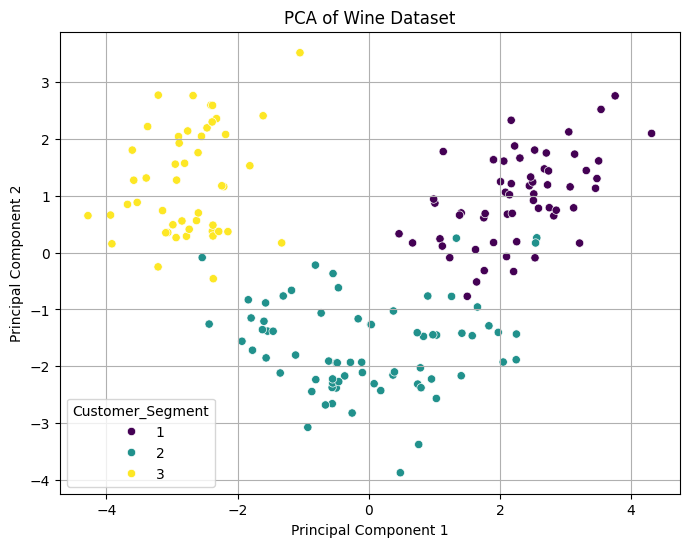

In [11]:
# Visualise the transformed data
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=reduced_data['PC1'],
    y=reduced_data['PC2'],
    hue=y,
    palette='viridis'
)

plt.title("PCA of Wine Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)

plt.show()

In [12]:
# Display the final reduced dataset
print("Original feature count:", X.shape[1])
print("Reduced feature count:", reduced_data.shape[1])

print("\nReduced dataset:")
display(reduced_data.head())

Original feature count: 13
Reduced feature count: 2

Reduced dataset:


,PC1,PC2
0,3.316751,1.443463
1,2.209465,-0.333393
2,2.516740,1.031151
3,3.757066,2.756372
4,1.008908,0.869831


In [13]:
# Inspect the variables contributing most to each principal component

loadings = pd.DataFrame(
    pca.components_[:2].T,
    index=X.columns,
    columns=["PC1", "PC2"]
)

print("Top variables contributing to PC1:")
display(
    loadings["PC1"]
    .abs()
    .sort_values(ascending=False)
    .head(5)
)

print("Top variables contributing to PC2:")
display(
    loadings["PC2"]
    .abs()
    .sort_values(ascending=False)
    .head(5)
)

Top variables contributing to PC1:


Flavanoids              0.422934
Total_Phenols           0.394661
OD280                   0.376167
Proanthocyanins         0.313429
Nonflavanoid_Phenols    0.298533
Name: PC1, dtype: float64

Top variables contributing to PC2:


Color_Intensity    0.529996
Alcohol            0.483652
Proline            0.364903
Ash                0.316069
Magnesium          0.299634
Name: PC2, dtype: float64